# Entrenamiento final del modelo — Proyecto Jimmy Quinga

**Proyecto:** Sistema predictivo para diagnóstico de fallas en equipos informáticos  
**Caso de estudio:** JAVERY, Ingeniería Humana y Tecnológica

Este notebook ejecuta de principio a fin la fase de **modelado y evaluación**.

## Diseño metodológico
- **Entrenamiento:** Open Repair / CompCat (laptops + desktops).
- **Validación operativa:** 4 casos reales de JAVERY reservados y no usados para entrenar.
- **Variable objetivo:** `tipo_falla`.
- **Predictores:** `tipo_equipo`, `marca`, `antiguedad_anios`, `sintoma`.
- Se excluyen variables posteriores al diagnóstico para evitar **data leakage**.
- Se comparan: Árbol de decisión, Random Forest, Naive Bayes, Regresión logística, SVM y KNN.
- La selección principal se realiza con **F1 macro en validación cruzada**, no solo con Accuracy.
- Se usa un conjunto de prueba estratificado del 20 % para evaluación final.

> Los datos públicos y los datos reales de JAVERY se mantienen metodológicamente separados.


## 1. Preparar entorno


In [1]:
!pip -q install scikit-learn joblib openpyxl

import os, re, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    ConfusionMatrixDisplay, classification_report,
    roc_auc_score, make_scorer
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 150)

print("Entorno preparado.")


Entorno preparado.


## 2. Descargar y consolidar Open Repair / CompCat

Se descargan directamente las fuentes oficiales. No se mezclan con JAVERY.


In [2]:
URL_LAPTOPS = "https://raw.githubusercontent.com/openrepair/data/master/quests/computers/compcat_laptops.csv"
URL_DESKTOPS = "https://raw.githubusercontent.com/openrepair/data/master/quests/computers/compcat_desktops.csv"

lap = pd.read_csv(URL_LAPTOPS)
desk = pd.read_csv(URL_DESKTOPS)

print("Laptops:", lap.shape)
print("Desktops:", desk.shape)

ora = pd.concat([lap, desk], ignore_index=True)
print("Total consolidado:", ora.shape)
display(ora.head())


Laptops: (3511, 11)
Desktops: (583, 11)
Total consolidado: (4094, 11)


,id_ords,data_provider,country,fault_type_id,fault_type,product_category,brand,repair_status,year_of_manufacture,event_date,problem
0,anstiftung_1033,anstiftung,DEU,18,System board,Laptop,Samsung,Unknown,NaN,2019-03-20,"Überhitzung, geht nicht mehr anwahrscheinlich Graphikkarte defekt"
1,anstiftung_1037,anstiftung,DEU,3,Configuration,Laptop,Unknown,Unknown,NaN,2019-03-19,Betriebssystem einrichten
2,anstiftung_1080,anstiftung,DEU,14,Overheating,Laptop,Lenovo,Fixed,2011.0,2019-04-03,Stürzt immer abWärmeleitpaste erneuern
3,anstiftung_1098,anstiftung,DEU,17,Power/battery,Laptop,macally,Fixed,NaN,2019-04-10,Lüftung kaputtneue Netzteil angebaut
4,anstiftung_1123,anstiftung,DEU,3,Configuration,Laptop,Unknown,Fixed,NaN,2019-01-17,"Kein Zugriff auf die externe Festplatte. Die Besucherin nutzte nur eine falsche angelegte Verknüpfung, um auf die Platte zuzugreifen. Eine kurze B..."


## 3. Limpieza para modelado

Criterios:
- eliminar duplicados;
- conservar registros con `problem` y `fault_type`;
- excluir `Unknown` como objetivo;
- normalizar tipo de equipo, marca y texto;
- calcular antigüedad cuando sea posible;
- conservar solamente clases con al menos 5 registros para garantizar partición estratificada y validación cruzada.


In [3]:
def limpiar_texto(x):
    if pd.isna(x):
        return np.nan
    x = str(x).strip()
    x = re.sub(r"\s+", " ", x)
    return x if x else np.nan

ora = ora.drop_duplicates().copy()
ora["sintoma"] = ora["problem"].map(limpiar_texto)
ora["tipo_falla"] = ora["fault_type"].map(limpiar_texto)
ora["marca"] = ora["brand"].map(limpiar_texto).fillna("Sin marca")
ora["marca"] = ora["marca"].replace({"Unknown":"Sin marca", "unknown":"Sin marca"})

ora["tipo_equipo"] = ora["product_category"].replace({
    "Laptop": "laptop",
    "Desktop computer": "desktop"
})

ora["event_date"] = pd.to_datetime(ora["event_date"], errors="coerce")
ora["year_of_manufacture"] = pd.to_numeric(ora["year_of_manufacture"], errors="coerce")
ora["antiguedad_anios"] = ora["event_date"].dt.year - ora["year_of_manufacture"]
ora.loc[(ora["antiguedad_anios"] < 0) | (ora["antiguedad_anios"] > 50), "antiguedad_anios"] = np.nan

ora = ora[
    ora["sintoma"].notna()
    & ora["tipo_falla"].notna()
    & (ora["tipo_falla"] != "Unknown")
    & ora["tipo_equipo"].isin(["laptop","desktop"])
].copy()

conteo = ora["tipo_falla"].value_counts()
clases_validas = conteo[conteo >= 5].index
ora = ora[ora["tipo_falla"].isin(clases_validas)].copy()
ora["fuente"] = "OPEN_REPAIR_COMPCAT"

print("Registros finales para modelado:", len(ora))
print("Clases objetivo:", ora["tipo_falla"].nunique())
display(ora["tipo_falla"].value_counts().to_frame("registros"))

print("\nNulos:")
display(
    ora[["tipo_equipo","marca","antiguedad_anios","sintoma","tipo_falla"]]
    .isna().sum().to_frame("nulos")
)

ora[["tipo_equipo","marca","antiguedad_anios","sintoma","tipo_falla","fuente","id_ords"]].to_csv(
    "OPEN_REPAIR_dataset_final_entrenamiento.csv",
    index=False,
    encoding="utf-8-sig"
)
print("\nGuardado: OPEN_REPAIR_dataset_final_entrenamiento.csv")


Registros finales para modelado: 2866
Clases objetivo: 19


,registros
tipo_falla,
Performance,433
Power/battery,389
Configuration,337
Integrated screen,277
Internal storage,210
Operating system,209
Boot,201
Ports/slots/connectors,138
Overheating,115



Nulos:


,nulos
tipo_equipo,0
marca,0
antiguedad_anios,2093
sintoma,0
tipo_falla,0



Guardado: OPEN_REPAIR_dataset_final_entrenamiento.csv


## 4. Análisis del balance de clases


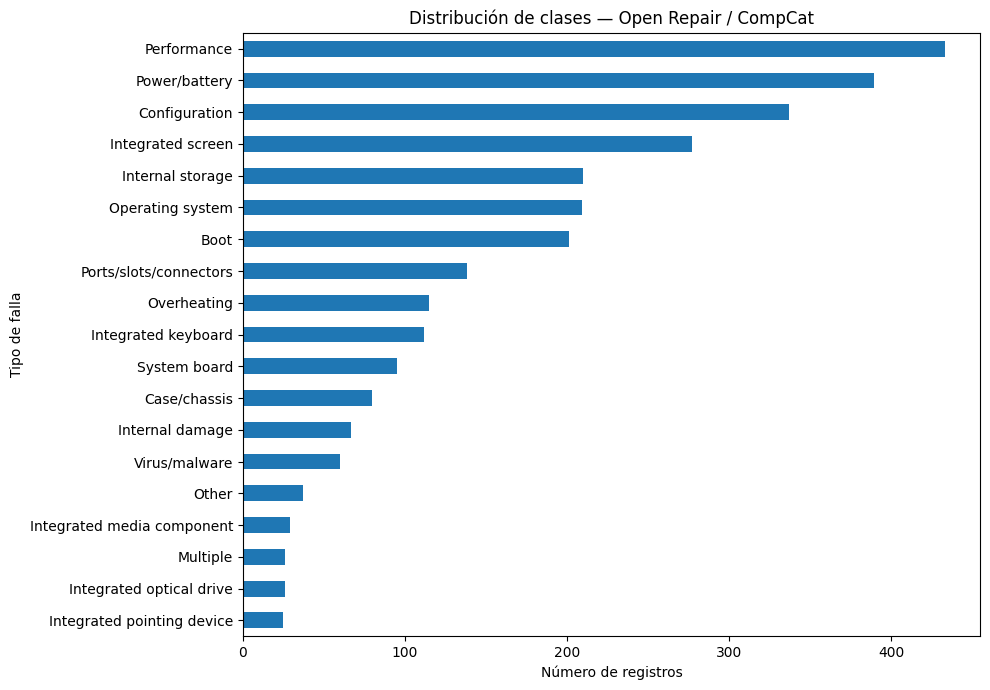

Clase menor: Integrated pointing device - 25 registros
Clase mayor: Performance - 433 registros
Razón de desbalance: 17.32


In [4]:
dist = ora["tipo_falla"].value_counts().sort_values()

plt.figure(figsize=(10, 7))
dist.plot(kind="barh")
plt.title("Distribución de clases — Open Repair / CompCat")
plt.xlabel("Número de registros")
plt.ylabel("Tipo de falla")
plt.tight_layout()
plt.savefig("distribucion_clases.png", dpi=180, bbox_inches="tight")
plt.show()

print("Clase menor:", dist.index[0], "-", dist.iloc[0], "registros")
print("Clase mayor:", dist.index[-1], "-", dist.iloc[-1], "registros")
print("Razón de desbalance:", round(dist.iloc[-1] / dist.iloc[0], 2))


## 5. División entrenamiento / prueba

El 80 % se usa para desarrollo y validación cruzada.  
El 20 % queda como prueba estratificada.


In [5]:
X = ora[["tipo_equipo","marca","antiguedad_anios","sintoma"]].copy()
y = ora["tipo_falla"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)
print("Clases train:", y_train.nunique())
print("Clases test:", y_test.nunique())


Entrenamiento: (2292, 4)
Prueba: (574, 4)
Clases train: 19
Clases test: 19


## 6. Preprocesamiento

Para el texto se usa **TF-IDF con n-gramas de caracteres (3–5)**. Esta representación tolera mejor errores de escritura y textos multilingües que depender únicamente de palabras exactas.

- `sintoma` → TF-IDF.
- `tipo_equipo` y `marca` → One-Hot Encoding.
- `antiguedad_anios` → imputación por mediana + escala 0–1.


In [6]:
preprocesador = ColumnTransformer(
    transformers=[
        ("texto", TfidfVectorizer(
            analyzer="char_wb",
            ngram_range=(3,5),
            min_df=2,
            max_features=12000,
            lowercase=True,
            sublinear_tf=True
        ), "sintoma"),
        ("categoricas", OneHotEncoder(handle_unknown="ignore"), ["tipo_equipo","marca"]),
        ("numerica", Pipeline([
            ("imputar", SimpleImputer(strategy="median")),
            ("escalar", MinMaxScaler())
        ]), ["antiguedad_anios"])
    ],
    remainder="drop"
)

print("Preprocesador definido.")


Preprocesador definido.


## 7. Modelos candidatos


In [7]:
modelos = {
    "Arbol_decision": DecisionTreeClassifier(
        random_state=RANDOM_STATE,
        class_weight="balanced",
        min_samples_leaf=2
    ),
    "Random_Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE,
        class_weight="balanced_subsample",
        n_jobs=-1
    ),
    "Naive_Bayes": MultinomialNB(alpha=0.5),
    "Regresion_logistica": LogisticRegression(
        max_iter=2500,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    "SVM": SVC(
        kernel="linear",
        probability=True,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "KNN": KNeighborsClassifier(
        n_neighbors=7,
        weights="distance",
        metric="cosine",
        algorithm="brute"
    )
}

print("Modelos:", list(modelos))


Modelos: ['Arbol_decision', 'Random_Forest', 'Naive_Bayes', 'Regresion_logistica', 'SVM', 'KNN']


## 8. Validación cruzada + evaluación en prueba

Se usa **F1 macro** como métrica principal porque todas las clases deben importar, incluso las menos frecuentes.


In [8]:
scoring = {
    "accuracy": make_scorer(accuracy_score),
    "precision_macro": make_scorer(precision_score, average="macro", zero_division=0),
    "recall_macro": make_scorer(recall_score, average="macro", zero_division=0),
    "f1_macro": make_scorer(f1_score, average="macro", zero_division=0)
}

min_clase_train = int(y_train.value_counts().min())
n_splits = max(2, min(3, min_clase_train))
cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)

resultados = []
modelos_entrenados = {}

for nombre, modelo in modelos.items():
    print(f"\n===== {nombre} =====")
    pipe = Pipeline([
        ("preprocesamiento", clone(preprocesador)),
        ("modelo", modelo)
    ])

    cv_res = cross_validate(
        pipe, X_train, y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        error_score="raise"
    )

    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)

    acc = accuracy_score(y_test, pred)
    prec = precision_score(y_test, pred, average="macro", zero_division=0)
    rec = recall_score(y_test, pred, average="macro", zero_division=0)
    f1m = f1_score(y_test, pred, average="macro", zero_division=0)
    f1w = f1_score(y_test, pred, average="weighted", zero_division=0)

    auc = np.nan
    try:
        proba = pipe.predict_proba(X_test)
        auc = roc_auc_score(
            y_test, proba,
            multi_class="ovr",
            average="macro",
            labels=pipe.classes_
        )
    except Exception as e:
        print("ROC-AUC no calculado:", str(e)[:120])

    fila = {
        "Modelo": nombre,
        "CV_Accuracy_media": cv_res["test_accuracy"].mean(),
        "CV_Precision_macro_media": cv_res["test_precision_macro"].mean(),
        "CV_Recall_macro_media": cv_res["test_recall_macro"].mean(),
        "CV_F1_macro_media": cv_res["test_f1_macro"].mean(),
        "Test_Accuracy": acc,
        "Test_Precision_macro": prec,
        "Test_Recall_macro": rec,
        "Test_F1_macro": f1m,
        "Test_F1_weighted": f1w,
        "Test_ROC_AUC_macro_OVR": auc
    }
    resultados.append(fila)
    modelos_entrenados[nombre] = pipe

    print("CV F1 macro:", round(fila["CV_F1_macro_media"], 4))
    print("Test Accuracy:", round(acc, 4))
    print("Test F1 macro:", round(f1m, 4))

resultados_df = pd.DataFrame(resultados).sort_values(
    "CV_F1_macro_media", ascending=False
).reset_index(drop=True)

resultados_df.to_csv("resultados_modelos.csv", index=False, encoding="utf-8-sig")
display(resultados_df)

print("Guardado: resultados_modelos.csv")



===== Arbol_decision =====
CV F1 macro: 0.5079
Test Accuracy: 0.5993
Test F1 macro: 0.5322

===== Random_Forest =====
CV F1 macro: 0.6195
Test Accuracy: 0.716
Test F1 macro: 0.6164

===== Naive_Bayes =====
CV F1 macro: 0.3181
Test Accuracy: 0.6237
Test F1 macro: 0.3885

===== Regresion_logistica =====
CV F1 macro: 0.5626
Test Accuracy: 0.6672
Test F1 macro: 0.5848

===== SVM =====
CV F1 macro: 0.576
Test Accuracy: 0.7038
Test F1 macro: 0.5834

===== KNN =====
CV F1 macro: 0.3878
Test Accuracy: 0.5279
Test F1 macro: 0.3858


,Modelo,CV_Accuracy_media,CV_Precision_macro_media,CV_Recall_macro_media,CV_F1_macro_media,Test_Accuracy,Test_Precision_macro,Test_Recall_macro,Test_F1_macro,Test_F1_weighted,Test_ROC_AUC_macro_OVR
0,Random_Forest,0.700262,0.727406,0.586083,0.619494,0.716028,0.646322,0.605490,0.616413,0.711332,0.926875
1,SVM,0.671902,0.619313,0.557501,0.576034,0.703833,0.588169,0.590126,0.583400,0.704821,0.929822
2,Regresion_logistica,0.643979,0.561574,0.584154,0.562615,0.667247,0.576445,0.610063,0.584795,0.683552,0.916437
3,Arbol_decision,0.592496,0.502357,0.530615,0.507937,0.599303,0.520968,0.561141,0.532163,0.604166,0.780748
4,KNN,0.518325,0.455051,0.371118,0.387824,0.527875,0.455605,0.370142,0.385825,0.512034,0.768025
5,Naive_Bayes,0.573298,0.535574,0.311249,0.318062,0.623693,0.609069,0.370350,0.388548,0.577294,0.888965


Guardado: resultados_modelos.csv


## 9. Selección del mejor modelo

El modelo ganador se selecciona por **F1 macro medio en validación cruzada**.


In [9]:
mejor_nombre = resultados_df.iloc[0]["Modelo"]
mejor_modelo = modelos_entrenados[mejor_nombre]

print("MEJOR MODELO:", mejor_nombre)
display(resultados_df.iloc[[0]])

joblib.dump(mejor_modelo, "mejor_modelo_diagnostico_fallas.joblib")
print("Guardado: mejor_modelo_diagnostico_fallas.joblib")


MEJOR MODELO: Random_Forest


,Modelo,CV_Accuracy_media,CV_Precision_macro_media,CV_Recall_macro_media,CV_F1_macro_media,Test_Accuracy,Test_Precision_macro,Test_Recall_macro,Test_F1_macro,Test_F1_weighted,Test_ROC_AUC_macro_OVR
0,Random_Forest,0.700262,0.727406,0.586083,0.619494,0.716028,0.646322,0.60549,0.616413,0.711332,0.926875


Guardado: mejor_modelo_diagnostico_fallas.joblib


## 10. Matriz de confusión y reporte de clasificación


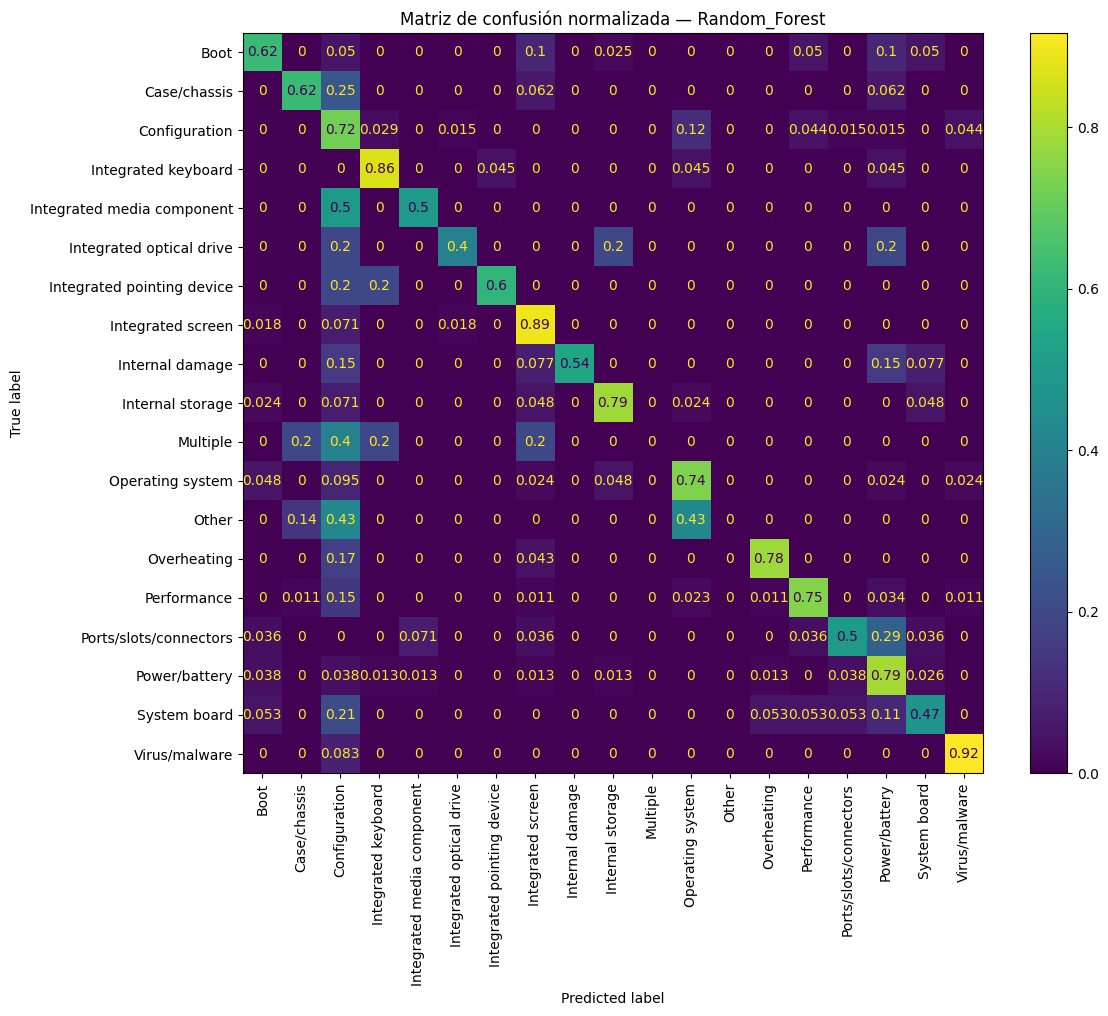

Guardado: reporte_clasificacion_mejor_modelo.csv
Guardado: matriz_confusion_mejor_modelo.png


In [10]:
pred_best = mejor_modelo.predict(X_test)

reporte = classification_report(
    y_test, pred_best,
    output_dict=True,
    zero_division=0
)
pd.DataFrame(reporte).T.to_csv(
    "reporte_clasificacion_mejor_modelo.csv",
    encoding="utf-8-sig"
)

fig, ax = plt.subplots(figsize=(12, 10))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_best,
    xticks_rotation=90,
    normalize="true",
    ax=ax
)
plt.title(f"Matriz de confusión normalizada — {mejor_nombre}")
plt.tight_layout()
plt.savefig("matriz_confusion_mejor_modelo.png", dpi=180, bbox_inches="tight")
plt.show()

print("Guardado: reporte_clasificacion_mejor_modelo.csv")
print("Guardado: matriz_confusion_mejor_modelo.png")


## 11. Predicciones del conjunto de prueba


In [11]:
predicciones_test = X_test.copy()
predicciones_test["real"] = y_test.values
predicciones_test["predicho"] = pred_best
predicciones_test["acierto"] = predicciones_test["real"] == predicciones_test["predicho"]

predicciones_test.to_csv(
    "predicciones_conjunto_prueba.csv",
    index=False,
    encoding="utf-8-sig"
)

display(predicciones_test.head(20))
print("Guardado: predicciones_conjunto_prueba.csv")


,tipo_equipo,marca,antiguedad_anios,sintoma,real,predicho,acierto
706,laptop,HP,NaN,geen voeding,Power/battery,Power/battery,True
263,laptop,IBM thinkpad,NaN,Laptop ~ It wont login. An error message keeps popping up,Configuration,Configuration,True
3861,desktop,Sin marca,4.0,Change of CPU and RAM,System board,Performance,False
140,laptop,Lenovo,NaN,USB-Treiber fehlen,Configuration,Configuration,True
3638,desktop,Asus,NaN,geen mailbox meer,Configuration,Configuration,True
1802,laptop,Acer,5.0,"booting to startup repair, hard drive making noise:solution: needs new harddrive and new operating system",Boot,Internal storage,False
44,laptop,Lenovo,NaN,"Den Klappmechanismus am Scharnier eines Lenovo Thinkpads hatten wir beim letzten Termin bereits versucht, mit Zweikomponentenkleber zu reparieren....",Case/chassis,Case/chassis,True
1000,laptop,Sin marca,NaN,Laptop Power socket faulty,Ports/slots/connectors,Ports/slots/connectors,True
2419,laptop,Dell,NaN,Freezes after a few minutes,Performance,Performance,True
2770,laptop,Toshiba,NaN,Laptop - No power -,Power/battery,Power/battery,True


Guardado: predicciones_conjunto_prueba.csv


# 10A. Gráfico comparativo de desempeño de los modelos

Este gráfico compara visualmente los seis algoritmos mediante **F1 macro de validación cruzada**, **F1 macro de prueba** y **Accuracy de prueba**. Para seleccionar el modelo ganador se mantiene como criterio principal el F1 macro medio en validación cruzada.


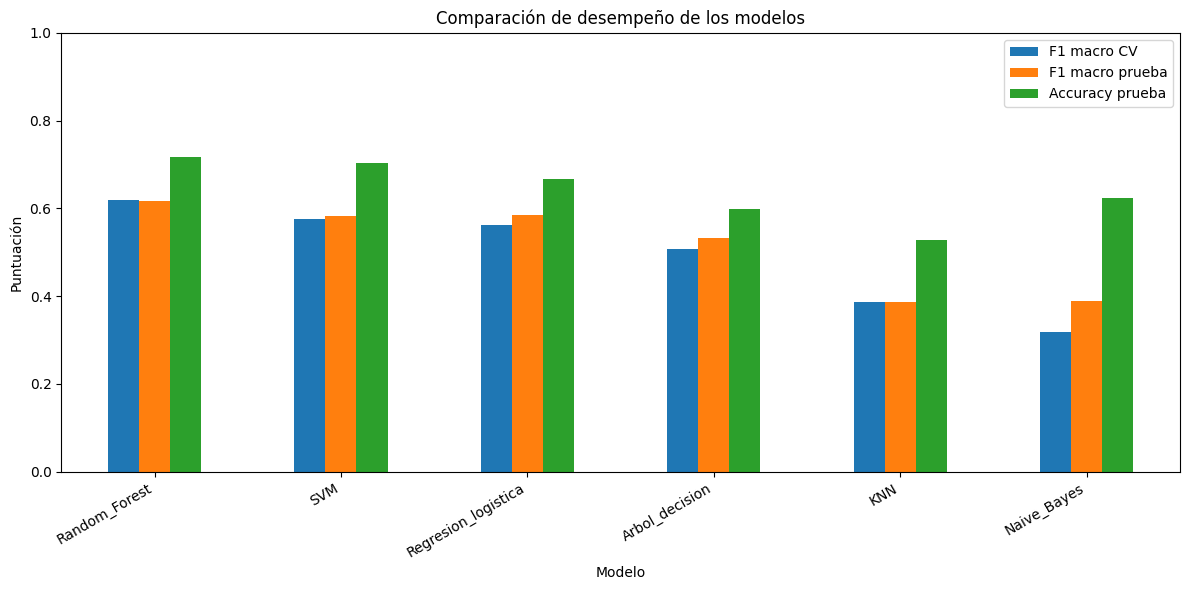

Guardado: comparacion_modelos.png


In [12]:
comparacion_plot = resultados_df[[
    "Modelo", "CV_F1_macro_media", "Test_F1_macro", "Test_Accuracy"
]].copy()

comparacion_plot.set_index("Modelo").plot(kind="bar", figsize=(12, 6))
plt.title("Comparación de desempeño de los modelos")
plt.ylabel("Puntuación")
plt.xlabel("Modelo")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.legend(["F1 macro CV", "F1 macro prueba", "Accuracy prueba"])
plt.tight_layout()
plt.savefig("comparacion_modelos.png", dpi=180, bbox_inches="tight")
plt.show()
print("Guardado: comparacion_modelos.png")


# 10B. Curva de aprendizaje del mejor modelo

La curva de aprendizaje muestra cómo evoluciona el rendimiento al aumentar la cantidad de datos de entrenamiento.

- Entrenamiento y validación cercanos y altos: buena generalización.
- Entrenamiento alto y validación claramente menor: posible **sobreajuste**.
- Ambas curvas bajas: posible **subajuste** o variables insuficientes.


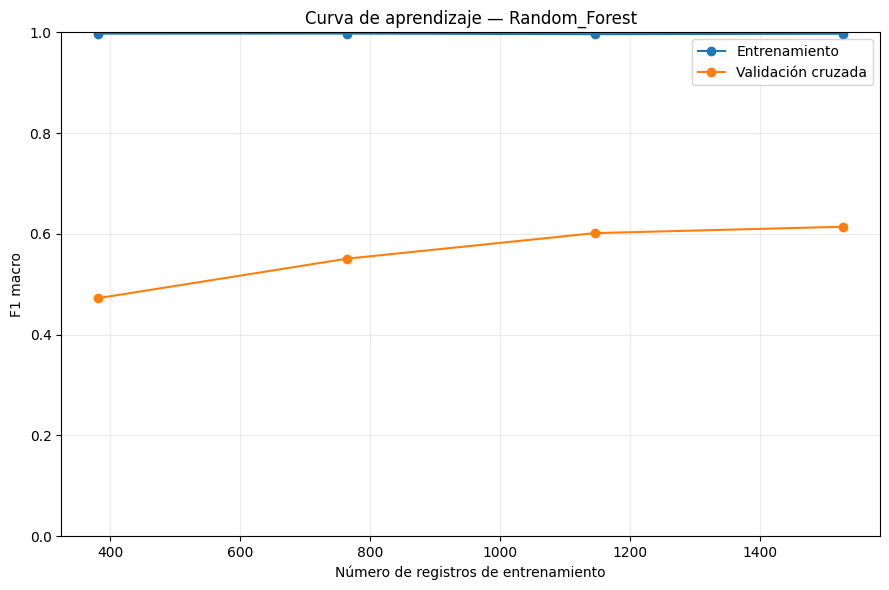

F1 train final: 0.9972
F1 validación final: 0.6142
Brecha train-validación: 0.383
Interpretación automática: existe una brecha importante; revisar posible sobreajuste.
Guardado: curva_aprendizaje_mejor_modelo.png
Guardado: curva_aprendizaje_datos.csv


In [13]:
from sklearn.model_selection import learning_curve

train_sizes_abs, train_scores, val_scores = learning_curve(
    estimator=clone(mejor_modelo),
    X=X_train,
    y=y_train,
    train_sizes=[0.25, 0.50, 0.75, 1.00],
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1,
    shuffle=True,
    random_state=RANDOM_STATE
)

train_mean = train_scores.mean(axis=1)
val_mean = val_scores.mean(axis=1)
train_std = train_scores.std(axis=1)
val_std = val_scores.std(axis=1)

curva_aprendizaje_df = pd.DataFrame({
    "tamano_entrenamiento": train_sizes_abs,
    "f1_train_media": train_mean,
    "f1_train_std": train_std,
    "f1_validacion_media": val_mean,
    "f1_validacion_std": val_std
})
curva_aprendizaje_df.to_csv("curva_aprendizaje_datos.csv", index=False, encoding="utf-8-sig")

plt.figure(figsize=(9, 6))
plt.plot(train_sizes_abs, train_mean, marker="o", label="Entrenamiento")
plt.plot(train_sizes_abs, val_mean, marker="o", label="Validación cruzada")
plt.title(f"Curva de aprendizaje — {mejor_nombre}")
plt.xlabel("Número de registros de entrenamiento")
plt.ylabel("F1 macro")
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.savefig("curva_aprendizaje_mejor_modelo.png", dpi=180, bbox_inches="tight")
plt.show()

gap_final = float(train_mean[-1] - val_mean[-1])
print("F1 train final:", round(float(train_mean[-1]), 4))
print("F1 validación final:", round(float(val_mean[-1]), 4))
print("Brecha train-validación:", round(gap_final, 4))
if gap_final > 0.15:
    print("Interpretación automática: existe una brecha importante; revisar posible sobreajuste.")
elif val_mean[-1] < 0.50:
    print("Interpretación automática: el desempeño de validación sigue siendo bajo; revisar subajuste, clases y variables.")
else:
    print("Interpretación automática: la generalización es razonable para este conjunto de datos.")
print("Guardado: curva_aprendizaje_mejor_modelo.png")
print("Guardado: curva_aprendizaje_datos.csv")


# 10C. Curvas ROC multiclase

Se muestran las curvas ROC de las **seis clases con mayor soporte en el conjunto de prueba** para mantener la figura legible. El ROC-AUC macro global permanece en la tabla comparativa de modelos.


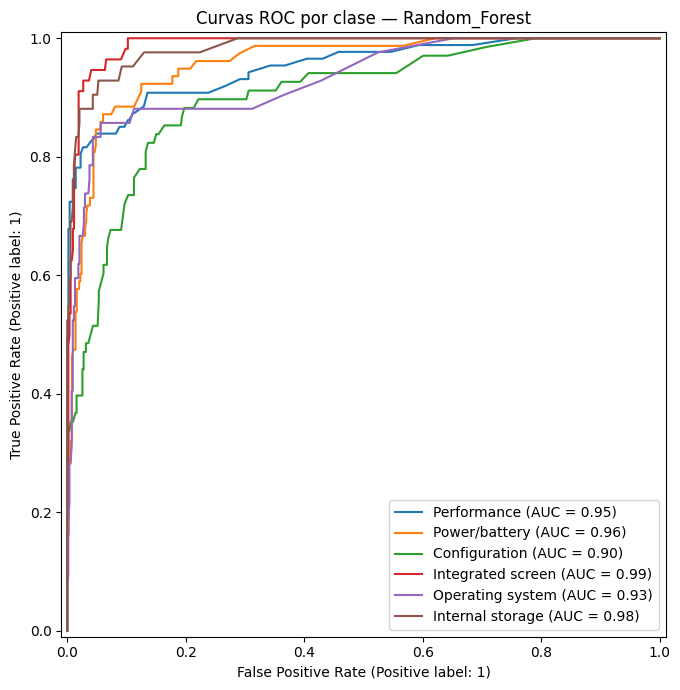

Clases mostradas: ['Performance', 'Power/battery', 'Configuration', 'Integrated screen', 'Operating system', 'Internal storage']
Guardado: roc_multiclase_mejor_modelo.png


In [14]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import RocCurveDisplay

try:
    proba_best = mejor_modelo.predict_proba(X_test)
    clases_modelo = list(mejor_modelo.classes_)
    y_bin = label_binarize(y_test, classes=clases_modelo)
    soporte_test = y_test.value_counts()
    clases_top = [c for c in soporte_test.index if c in clases_modelo][:6]

    fig, ax = plt.subplots(figsize=(10, 7))
    for clase in clases_top:
        idx = clases_modelo.index(clase)
        if y_bin[:, idx].sum() > 0:
            RocCurveDisplay.from_predictions(
                y_bin[:, idx], proba_best[:, idx], name=str(clase), ax=ax
            )
    plt.title(f"Curvas ROC por clase — {mejor_nombre}")
    plt.tight_layout()
    plt.savefig("roc_multiclase_mejor_modelo.png", dpi=180, bbox_inches="tight")
    plt.show()
    print("Clases mostradas:", clases_top)
    print("Guardado: roc_multiclase_mejor_modelo.png")
except Exception as e:
    print("No fue posible generar ROC multiclase:", e)


# 10D. Curvas Precision–Recall

Estas curvas ayudan a evaluar el modelo cuando las clases están desbalanceadas. Se muestran las mismas seis clases con mayor soporte del conjunto de prueba.


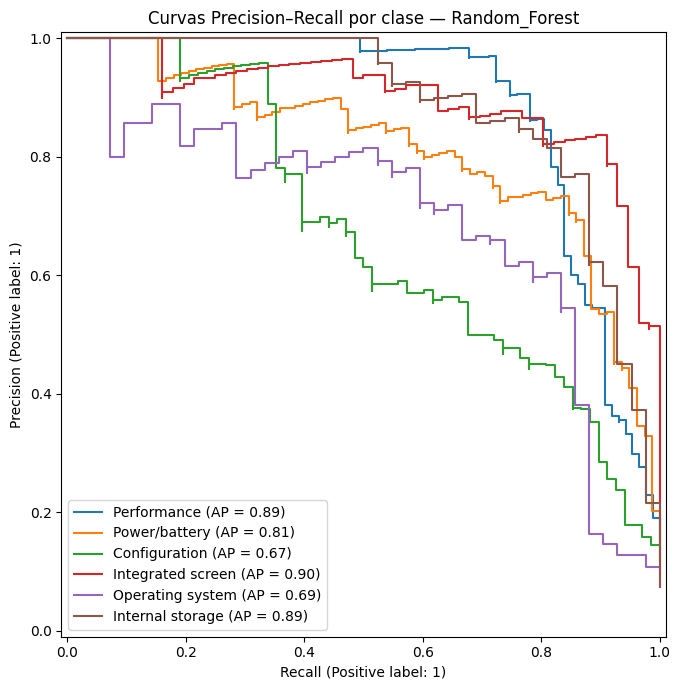

Guardado: precision_recall_mejor_modelo.png


In [15]:
from sklearn.metrics import PrecisionRecallDisplay

try:
    fig, ax = plt.subplots(figsize=(10, 7))
    for clase in clases_top:
        idx = clases_modelo.index(clase)
        if y_bin[:, idx].sum() > 0:
            PrecisionRecallDisplay.from_predictions(
                y_bin[:, idx], proba_best[:, idx], name=str(clase), ax=ax
            )
    plt.title(f"Curvas Precision–Recall por clase — {mejor_nombre}")
    plt.tight_layout()
    plt.savefig("precision_recall_mejor_modelo.png", dpi=180, bbox_inches="tight")
    plt.show()
    print("Guardado: precision_recall_mejor_modelo.png")
except Exception as e:
    print("No fue posible generar Precision–Recall:", e)


# 10E. F1-score por tipo de falla

Este gráfico permite detectar las categorías de falla con mejor y peor reconocimiento y sustenta la discusión sobre clases minoritarias.


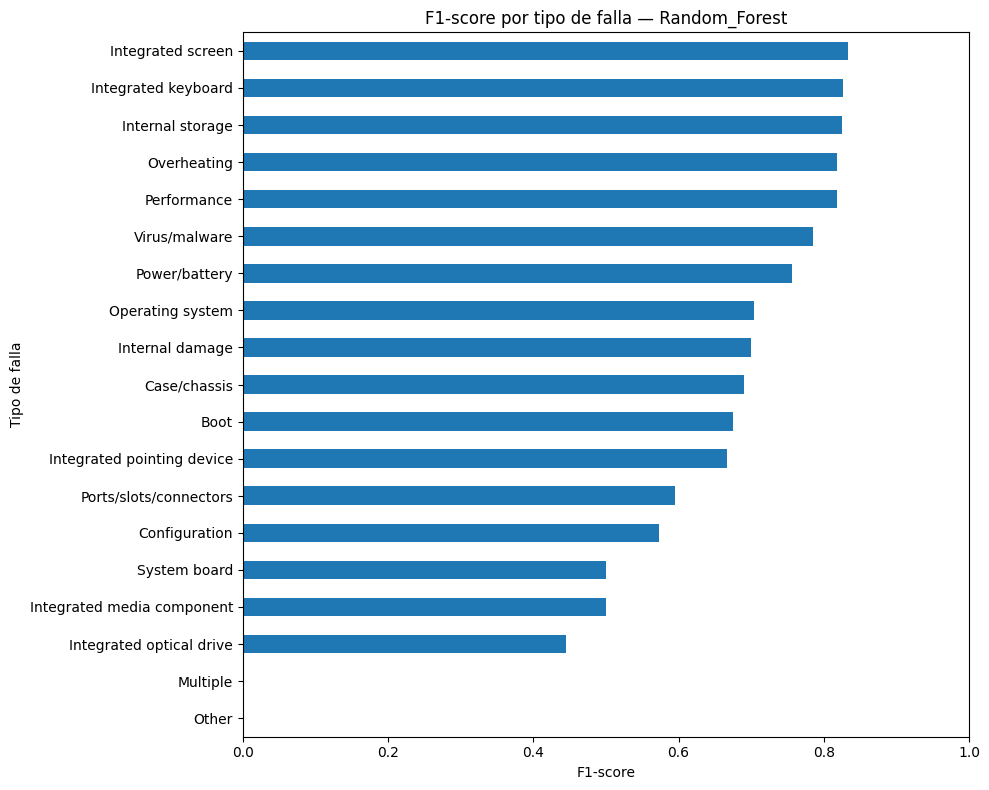

Guardado: f1_por_clase.png
Guardado: metricas_por_clase.csv


In [16]:
reporte_df = pd.DataFrame(reporte).T.copy()
clases_reporte = [
    idx for idx in reporte_df.index
    if idx not in ["accuracy", "macro avg", "weighted avg"]
]
f1_clases = reporte_df.loc[clases_reporte, ["f1-score", "support"]].sort_values("f1-score")

f1_clases["f1-score"].plot(kind="barh", figsize=(10, 8))
plt.title(f"F1-score por tipo de falla — {mejor_nombre}")
plt.xlabel("F1-score")
plt.ylabel("Tipo de falla")
plt.xlim(0, 1)
plt.tight_layout()
plt.savefig("f1_por_clase.png", dpi=180, bbox_inches="tight")
plt.show()

f1_clases.to_csv("metricas_por_clase.csv", encoding="utf-8-sig")
print("Guardado: f1_por_clase.png")
print("Guardado: metricas_por_clase.csv")


# 10F. Aciertos y errores del conjunto de prueba


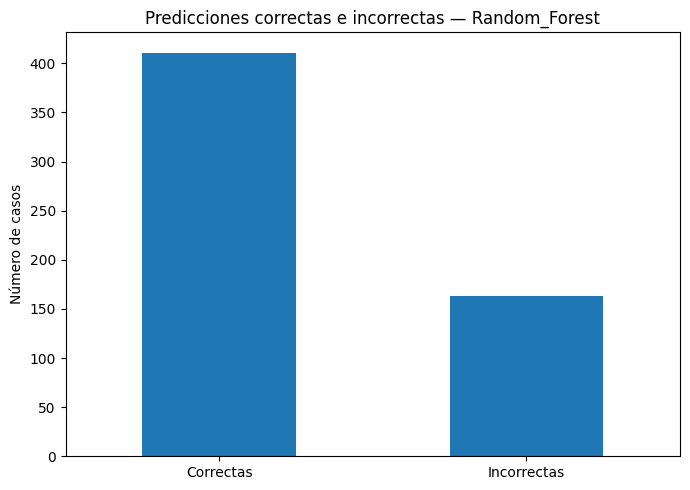

Correctas      411
Incorrectas    163
dtype: int64
Guardado: aciertos_errores_prueba.png


In [17]:
conteo_aciertos = pd.Series({
    "Correctas": int((pred_best == y_test.to_numpy()).sum()),
    "Incorrectas": int((pred_best != y_test.to_numpy()).sum())
})
conteo_aciertos.plot(kind="bar", figsize=(7, 5))
plt.title(f"Predicciones correctas e incorrectas — {mejor_nombre}")
plt.ylabel("Número de casos")
plt.xlabel("")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("aciertos_errores_prueba.png", dpi=180, bbox_inches="tight")
plt.show()
print(conteo_aciertos)
print("Guardado: aciertos_errores_prueba.png")


# 10G. Evidencias gráficas para la memoria técnica

Al finalizar el notebook se generan automáticamente:

1. `distribucion_clases.png` — balance de la variable objetivo.
2. `comparacion_modelos.png` — comparación de los seis algoritmos.
3. `curva_aprendizaje_mejor_modelo.png` — evolución de F1 con más datos.
4. `matriz_confusion_mejor_modelo.png` — errores de clasificación.
5. `roc_multiclase_mejor_modelo.png` — capacidad discriminativa por clase.
6. `precision_recall_mejor_modelo.png` — evaluación ante desbalance.
7. `f1_por_clase.png` — rendimiento por tipo de falla.
8. `aciertos_errores_prueba.png` — resumen de aciertos y errores.

Estos resultados complementan Accuracy, Precision, Recall, F1 y ROC-AUC y permiten justificar técnicamente la selección del modelo.


# ENTORNO AISLADO — VALIDACIÓN OPERATIVA JAVERY

Los siguientes 4 registros reales de JAVERY fueron reservados y **no participaron en el entrenamiento**.

Esta validación es exploratoria porque cuatro casos no constituyen una muestra estadística suficiente.


In [18]:
javery_val = pd.DataFrame([
    {
        "tipo_equipo":"laptop", "marca":"HP", "antiguedad_anios":16,
        "sintoma":"no enciende", "tipo_falla":"System board",
        "fuente":"JAVERY", "orden_servicio":"OS-003"
    },
    {
        "tipo_equipo":"laptop", "marca":"Lenovo", "antiguedad_anios":8,
        "sintoma":"no da imagen", "tipo_falla":"System board",
        "fuente":"JAVERY", "orden_servicio":"OS-004"
    },
    {
        "tipo_equipo":"desktop", "marca":"Sin marca", "antiguedad_anios":16,
        "sintoma":"no enciende", "tipo_falla":"Power/battery",
        "fuente":"JAVERY", "orden_servicio":"OS-005"
    },
    {
        "tipo_equipo":"desktop", "marca":"Sin marca", "antiguedad_anios":11,
        "sintoma":"no arranca el sistema operativo; logo detenido", "tipo_falla":"Boot",
        "fuente":"JAVERY", "orden_servicio":"OS-006"
    }
])

X_jav = javery_val[["tipo_equipo","marca","antiguedad_anios","sintoma"]]
y_jav = javery_val["tipo_falla"]

javery_val["prediccion_modelo"] = mejor_modelo.predict(X_jav)
javery_val["acierto"] = javery_val["tipo_falla"] == javery_val["prediccion_modelo"]

try:
    proba_jav = mejor_modelo.predict_proba(X_jav)
    javery_val["confianza_max"] = proba_jav.max(axis=1)
except Exception:
    javery_val["confianza_max"] = np.nan

acc_jav = accuracy_score(y_jav, javery_val["prediccion_modelo"])

print("Aciertos JAVERY:", int(javery_val["acierto"].sum()), "de", len(javery_val))
print("Accuracy operativa exploratoria:", round(acc_jav, 4))
print("ADVERTENCIA: no interpretar 4 casos como estimación estadística de desempeño.")

javery_val.to_csv(
    "predicciones_JAVERY_validacion.csv",
    index=False,
    encoding="utf-8-sig"
)
display(javery_val)

print("Guardado: predicciones_JAVERY_validacion.csv")


Aciertos JAVERY: 0 de 4
Accuracy operativa exploratoria: 0.0
ADVERTENCIA: no interpretar 4 casos como estimación estadística de desempeño.


,tipo_equipo,marca,antiguedad_anios,sintoma,tipo_falla,fuente,orden_servicio,prediccion_modelo,acierto,confianza_max
0,laptop,HP,16,no enciende,System board,JAVERY,OS-003,Configuration,False,0.370
1,laptop,Lenovo,8,no da imagen,System board,JAVERY,OS-004,Configuration,False,0.415
2,desktop,Sin marca,16,no enciende,Power/battery,JAVERY,OS-005,Configuration,False,0.340
3,desktop,Sin marca,11,no arranca el sistema operativo; logo detenido,Boot,JAVERY,OS-006,Configuration,False,0.255


Guardado: predicciones_JAVERY_validacion.csv


## 12. Resumen automático para la memoria técnica


In [19]:
ganador = resultados_df.iloc[0]

resumen = f'''
RESUMEN DEL ENTRENAMIENTO

Registros Open Repair usados: {len(ora)}
Número de clases: {ora["tipo_falla"].nunique()}
Partición: 80 % entrenamiento / 20 % prueba
Validación cruzada: {n_splits}-fold estratificada
Métrica principal de selección: F1 macro

Mejor modelo: {mejor_nombre}
CV F1 macro medio: {ganador["CV_F1_macro_media"]:.4f}
Test Accuracy: {ganador["Test_Accuracy"]:.4f}
Test Precision macro: {ganador["Test_Precision_macro"]:.4f}
Test Recall macro: {ganador["Test_Recall_macro"]:.4f}
Test F1 macro: {ganador["Test_F1_macro"]:.4f}
Test ROC-AUC macro OVR: {ganador["Test_ROC_AUC_macro_OVR"]:.4f}

Validación operativa JAVERY:
Aciertos: {int(javery_val["acierto"].sum())}/{len(javery_val)}
Accuracy exploratoria: {acc_jav:.4f}

Interpretación:
El corpus público Open Repair/CompCat se utilizó como entorno de entrenamiento
experimental, mientras que los registros reales de JAVERY se conservaron fuera
del entrenamiento y se emplearon únicamente como validación operativa inicial.
Las variables posteriores al diagnóstico fueron excluidas para evitar fuga de
información. La selección del modelo se realizó por F1 macro en validación cruzada.
'''

print(resumen)

with open("resumen_entrenamiento_memoria_tecnica.txt","w",encoding="utf-8") as f:
    f.write(resumen)

print("Guardado: resumen_entrenamiento_memoria_tecnica.txt")



RESUMEN DEL ENTRENAMIENTO

Registros Open Repair usados: 2866
Número de clases: 19
Partición: 80 % entrenamiento / 20 % prueba
Validación cruzada: 3-fold estratificada
Métrica principal de selección: F1 macro

Mejor modelo: Random_Forest
CV F1 macro medio: 0.6195
Test Accuracy: 0.7160
Test Precision macro: 0.6463
Test Recall macro: 0.6055
Test F1 macro: 0.6164
Test ROC-AUC macro OVR: 0.9269

Validación operativa JAVERY:
Aciertos: 0/4
Accuracy exploratoria: 0.0000

Interpretación:
El corpus público Open Repair/CompCat se utilizó como entorno de entrenamiento
experimental, mientras que los registros reales de JAVERY se conservaron fuera
del entrenamiento y se emplearon únicamente como validación operativa inicial.
Las variables posteriores al diagnóstico fueron excluidas para evitar fuga de
información. La selección del modelo se realizó por F1 macro en validación cruzada.

Guardado: resumen_entrenamiento_memoria_tecnica.txt


## 13. Empaquetar todos los resultados


In [20]:
archivos = [
    "OPEN_REPAIR_dataset_final_entrenamiento.csv",
    "distribucion_clases.png",
    "comparacion_modelos.png",
    "curva_aprendizaje_mejor_modelo.png",
    "curva_aprendizaje_datos.csv",
    "roc_multiclase_mejor_modelo.png",
    "precision_recall_mejor_modelo.png",
    "f1_por_clase.png",
    "metricas_por_clase.csv",
    "aciertos_errores_prueba.png",
    "resultados_modelos.csv",
    "mejor_modelo_diagnostico_fallas.joblib",
    "reporte_clasificacion_mejor_modelo.csv",
    "matriz_confusion_mejor_modelo.png",
    "predicciones_conjunto_prueba.csv",
    "predicciones_JAVERY_validacion.csv",
    "resumen_entrenamiento_memoria_tecnica.txt"
]

with zipfile.ZipFile(
    "RESULTADOS_ENTRENAMIENTO_JIMMY.zip",
    "w",
    zipfile.ZIP_DEFLATED
) as z:
    for a in archivos:
        if os.path.exists(a):
            z.write(a)

print("LISTO: RESULTADOS_ENTRENAMIENTO_JIMMY.zip")
print("\nArchivos generados:")
for a in archivos:
    print("-", a)

from google.colab import files
files.download("RESULTADOS_ENTRENAMIENTO_JIMMY.zip")


LISTO: RESULTADOS_ENTRENAMIENTO_JIMMY.zip

Archivos generados:
- OPEN_REPAIR_dataset_final_entrenamiento.csv
- distribucion_clases.png
- comparacion_modelos.png
- curva_aprendizaje_mejor_modelo.png
- curva_aprendizaje_datos.csv
- roc_multiclase_mejor_modelo.png
- precision_recall_mejor_modelo.png
- f1_por_clase.png
- metricas_por_clase.csv
- aciertos_errores_prueba.png
- resultados_modelos.csv
- mejor_modelo_diagnostico_fallas.joblib
- reporte_clasificacion_mejor_modelo.csv
- matriz_confusion_mejor_modelo.png
- predicciones_conjunto_prueba.csv
- predicciones_JAVERY_validacion.csv
- resumen_entrenamiento_memoria_tecnica.txt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Qué sigue después de este notebook

Cuando termine:

1. **Conservar `resultados_modelos.csv`** para la tabla comparativa de la memoria técnica.
2. **Conservar `matriz_confusion_mejor_modelo.png`** como evidencia del entrenamiento.
3. **Conservar `predicciones_JAVERY_validacion.csv`** para explicar la validación operativa aislada.
4. Continuar con la siguiente fase del proyecto: **Power BI / dashboard e interpretación de resultados**.

> Si el tutor exige evidencia específicamente generada en Orange Data Mining, se replica el modelo ganador en Orange usando el mismo dataset final y se documentan las capturas. El criterio experimental y la separación JAVERY/Open Repair se mantienen.
